# 04 — Baseline Models (XGBoost & LightGBM, tanpa resampling)

Notebook ini melatih model **baseline**:

- Data: `X_train`/`y_train` hasil split 80:20 stratified (random_state=42).
- **Tanpa SMOTE-ENN** (data train asli yang masih imbalanced).
- **Hyperparameter default** (belum tuning).
- Evaluasi pada `X_test`/`y_test` (test set yang murni, tidak pernah diresampling).

Metrik: Confusion Matrix, Accuracy, Precision, Recall, F1-score, ROC-AUC.
Kelas positif = `Stunted` (1), karena recall pada kelas ini adalah prioritas
(false negative berarti balita stunting terlewat intervensi).

In [1]:
import os
import pandas as pd
import numpy as np
from joblib import load
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
)
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

sns.set_theme(style="whitegrid")

RANDOM_STATE = 42
DATA_DIR = "../data/processed"
METRICS_DIR = "../results/metrics"
LABELS = ["Not Stunted", "Stunted"]
POS_LABEL = 1

In [2]:
X_train = load(os.path.join(DATA_DIR, "X_train.joblib"))
X_test = load(os.path.join(DATA_DIR, "X_test.joblib"))
y_train = load(os.path.join(DATA_DIR, "y_train.joblib"))
y_test = load(os.path.join(DATA_DIR, "y_test.joblib"))

print("X_train", X_train.shape, "| X_test", X_test.shape)
print("y_train", y_train.shape, "| y_test", y_test.shape)
print("Distribusi y_train:", y_train.value_counts().sort_index().to_dict())

X_train (32051, 4) | X_test (8013, 4)
y_train (32051,) | y_test (8013,)
Distribusi y_train: {0: 19091, 1: 12960}


## 1. Model Baseline (default hyperparameter)

`random_state=42` dipakai agar proses stokastik internal reproducible (sesuai
aturan konsistensi), **bukan** bagian dari tuning. Semua parameter lain dibiarkan
default.

In [3]:
models = {
    "XGBoost": XGBClassifier(
        random_state=RANDOM_STATE, eval_metric="logloss", verbosity=0
    ),
    "LightGBM": LGBMClassifier(
        random_state=RANDOM_STATE, verbosity=-1
    ),
}

## 2. Latih & Evaluasi

In [4]:
def evaluate_model(name, model):
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1]

    tn, fp, fn, tp = confusion_matrix(y_test, y_pred, labels=[0, 1]).ravel()

    metrics = {
        "model": name,
        "accuracy": accuracy_score(y_test, y_pred),
        "precision": precision_score(y_test, y_pred, pos_label=POS_LABEL),
        "recall": recall_score(y_test, y_pred, pos_label=POS_LABEL),
        "f1_score": f1_score(y_test, y_pred, pos_label=POS_LABEL),
        "roc_auc": roc_auc_score(y_test, y_proba),
        "tn": tn,
        "fp": fp,
        "fn": fn,
        "tp": tp,
    }
    return metrics, y_pred, y_proba


results = {}
rows = []
for name, model in models.items():
    metrics, y_pred, y_proba = evaluate_model(name, model)
    results[name] = (y_pred, y_proba)
    rows.append(metrics)

    print(f"===== {name} =====")
    print(classification_report(y_test, y_pred, target_names=LABELS, digits=4))

    cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
    cm_df = pd.DataFrame(
        cm,
        index=[f"Actual {l}" for l in LABELS],
        columns=[f"Pred {l}" for l in LABELS],
    )
    print("Confusion Matrix:")
    print(cm_df)
    print()

===== XGBoost =====
              precision    recall  f1-score   support

 Not Stunted     0.9599    0.9721    0.9660      4773
     Stunted     0.9582    0.9401    0.9491      3240

    accuracy                         0.9592      8013
   macro avg     0.9590    0.9561    0.9575      8013
weighted avg     0.9592    0.9592    0.9591      8013

Confusion Matrix:
                    Pred Not Stunted  Pred Stunted
Actual Not Stunted              4640           133
Actual Stunted                   194          3046



===== LightGBM =====
              precision    recall  f1-score   support

 Not Stunted     0.9632    0.9715    0.9674      4773
     Stunted     0.9575    0.9454    0.9514      3240

    accuracy                         0.9609      8013
   macro avg     0.9604    0.9584    0.9594      8013
weighted avg     0.9609    0.9609    0.9609      8013

Confusion Matrix:
                    Pred Not Stunted  Pred Stunted
Actual Not Stunted              4637           136
Actual Stunted                   177          3063



## 3. Kumpulkan Hasil & Simpan CSV

In [5]:
results_df = pd.DataFrame(rows)
results_df


,model,accuracy,precision,recall,f1_score,roc_auc,tn,fp,fn,tp
0,XGBoost,0.959191,0.958163,0.940123,0.949057,0.992883,4640,133,194,3046
1,LightGBM,0.960938,0.957487,0.945370,0.951390,0.993038,4637,136,177,3063


In [6]:
os.makedirs(METRICS_DIR, exist_ok=True)
out_path = os.path.join(METRICS_DIR, "baseline_results.csv")
results_df.to_csv(out_path, index=False)
print(f"Tersimpan: {out_path}")

Tersimpan: ../results/metrics\baseline_results.csv


## 4. Confusion Matrix (visual)

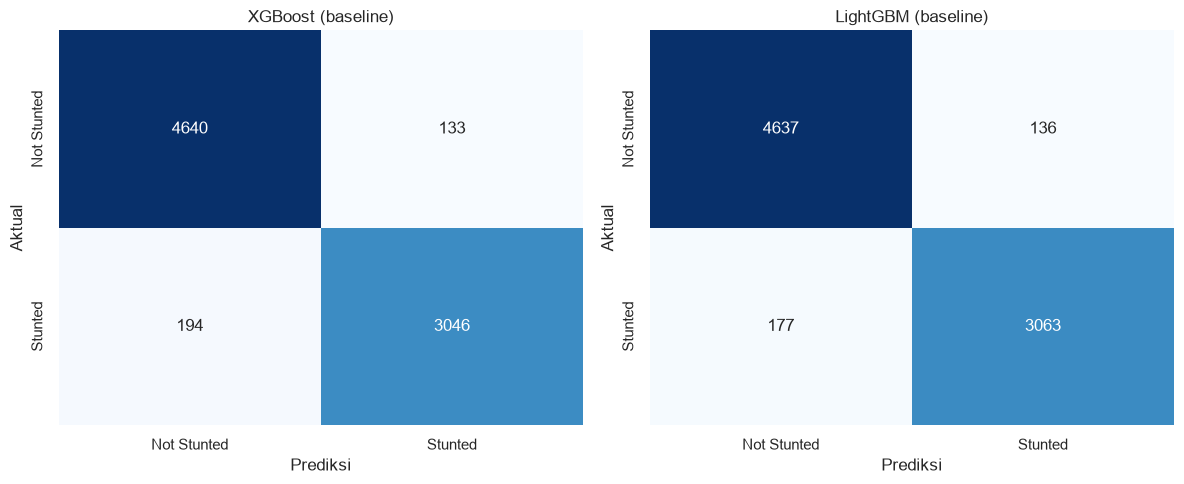

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, (name, _) in zip(axes, models.items()):
    y_pred, _ = results[name]
    cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=LABELS, yticklabels=LABELS, ax=ax)
    ax.set_title(f"{name} (baseline)")
    ax.set_xlabel("Prediksi")
    ax.set_ylabel("Aktual")

plt.tight_layout()
plt.show()